Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)
import tensorflow as tf

Load the data

In [ ]:
df = pd.read_csv('synthetic_customer_churn_100k.csv')
print(df.shape)
df.head()

(100000, 9)


,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No


Understand the data

In [ ]:
df.info()
print(df.describe())
print("Missing:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df['Churn'].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   CustomerID      100000 non-null  int64  
 1   Age             100000 non-null  int64  
 2   Gender          100000 non-null  object 
 3   Tenure          100000 non-null  int64  
 4   MonthlyCharges  100000 non-null  float64
 5   Contract        100000 non-null  object 
 6   PaymentMethod   100000 non-null  object 
 7   TotalCharges    100000 non-null  float64
 8   Churn           100000 non-null  object 
dtypes: float64(2), int64(3), object(4)
memory usage: 6.9+ MB
          CustomerID            Age         Tenure  MonthlyCharges  \
count  100000.000000  100000.000000  100000.000000   100000.000000   
mean    50000.500000      49.027240      36.527090       79.974933   
std     28867.657797      18.177862      20.789552       40.491961   
min         1.000000      18.000000       1

Visualise (EDA)

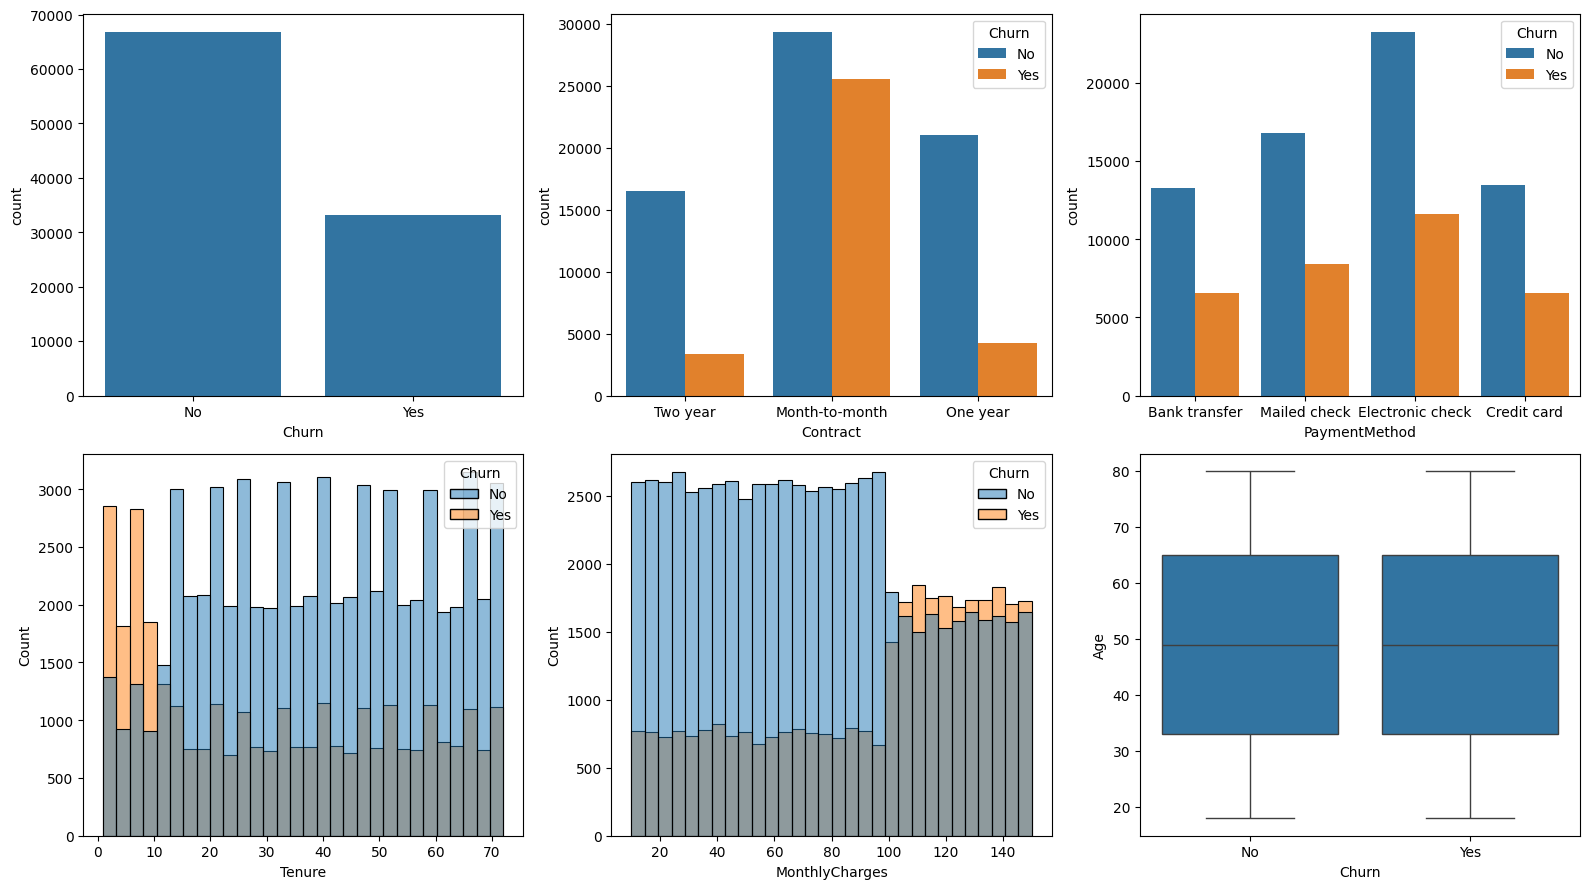

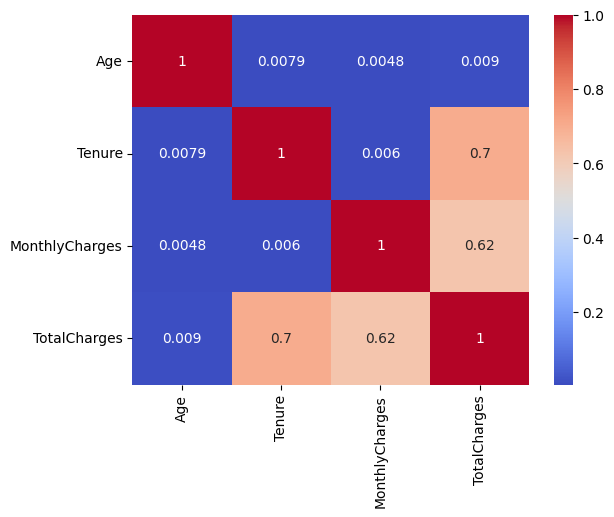

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(x='Churn', data=df, ax=ax[0,0])
sns.countplot(x='Contract', hue='Churn', data=df, ax=ax[0,1])
sns.countplot(x='PaymentMethod', hue='Churn', data=df, ax=ax[0,2])
sns.histplot(data=df, x='Tenure', hue='Churn', bins=30, ax=ax[1,0])
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30, ax=ax[1,1])
sns.boxplot(x='Churn', y='Age', data=df, ax=ax[1,2])
plt.tight_layout(); plt.show()

sns.heatmap(df.select_dtypes('number').drop(columns='CustomerID').corr(),
            annot=True, cmap='coolwarm'); plt.show()

Clean and prepare

In [ ]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})   # target to 0/1
X = df.drop(columns=['CustomerID', 'Churn'])           # ID has no predictive value
y = df['Churn']

num_cols = ['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = ['Gender', 'Contract', 'PaymentMethod']

preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])

Train-test split (80:20)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

X_train_p = preprocess.fit_transform(X_train)   # fit on train ONLY
X_test_p  = preprocess.transform(X_test)
X_train_p = X_train_p.toarray() if hasattr(X_train_p, 'toarray') else X_train_p
X_test_p  = X_test_p.toarray()  if hasattr(X_test_p, 'toarray')  else X_test_p
print(X_train_p.shape)

(80000, 7) (20000, 7)
(80000, 14)


Baseline models

In [ ]:
def evaluate(name, y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {'Model': name,
            'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'ROC-AUC': roc_auc_score(y_true, prob)}

lr = LogisticRegression(max_iter=1000).fit(X_train_p, y_train)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                            random_state=42, n_jobs=-1).fit(X_train_p, y_train)

results = [evaluate('Logistic Regression', y_test, lr.predict_proba(X_test_p)[:,1]),
           evaluate('Random Forest',        y_test, rf.predict_proba(X_test_p)[:,1])]
pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.72350,0.608191,0.465983,0.527673,0.771893
1,Random Forest,0.73845,0.630071,0.510786,0.564192,0.793179


Build and train the neural network

In [ ]:
tf.random.set_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_p.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
model.summary()

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8,
                                      restore_best_weights=True)
history = model.fit(X_train_p, y_train, validation_split=0.1,
                    epochs=100, batch_size=256, callbacks=[es], verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7058 - auc: 0.7341 - loss: 0.5513 - val_accuracy: 0.7454 - val_auc: 0.7880 - val_loss: 0.5055
Epoch 2/100
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7318 - auc: 0.7804 - loss: 0.5089 - val_accuracy: 0.7533 - val_auc: 0.7943 - val_loss: 0.4923
Epoch 3/100
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7346 - auc: 0.7850 - loss: 0.5007 - val_accuracy: 0.7552 - val_auc: 0.7967 - val_loss: 0.4846
Epoch 4/100
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7396 - auc: 0.7899 - loss: 0.4935 - val_accuracy: 0.7538 - val_auc: 0.7979 - val_loss: 0.4798
Epoch 5/100
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7423 - auc: 0.7916 - loss: 0.4885 - val_accuracy: 0.7567 - val_auc: 0.7989 - val_loss: 0.4756
Epoch 6/100
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7434 - auc: 0.7931 - loss: 0.4856 - val_accuracy: 0.7573 - val_auc: 0.7991 - val_loss: 0.4731
Epoch 7/100
282/282 ━━━━━━━━━━━━━

Plot the learning curves

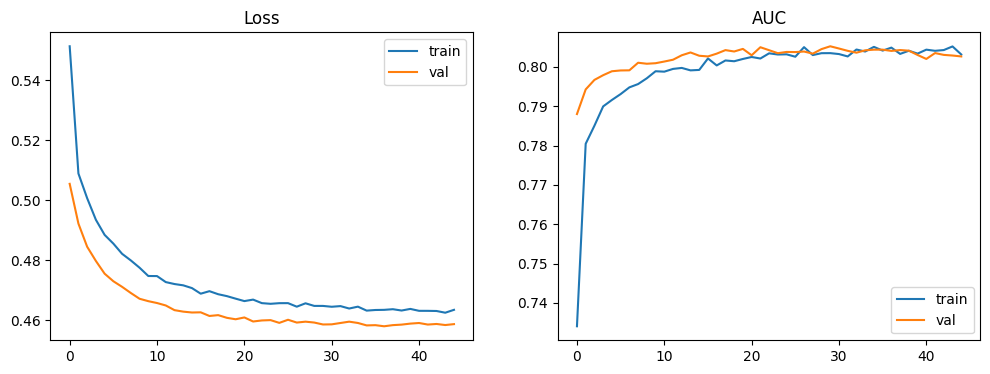

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='train'); ax[0].plot(history.history['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history.history['auc'], label='train'); ax[1].plot(history.history['val_auc'], label='val')
ax[1].set_title('AUC'); ax[1].legend()
plt.show()

Evaluate on the test set

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7235,0.6082,0.4660,0.5277,0.7719
1,Random Forest,0.7385,0.6301,0.5108,0.5642,0.7932
2,Neural Network,0.7614,0.6698,0.5526,0.6056,0.8037


              precision    recall  f1-score   support

           0       0.80      0.86      0.83     13371
           1       0.67      0.55      0.61      6629

    accuracy                           0.76     20000
   macro avg       0.73      0.71      0.72     20000
weighted avg       0.75      0.76      0.75     20000



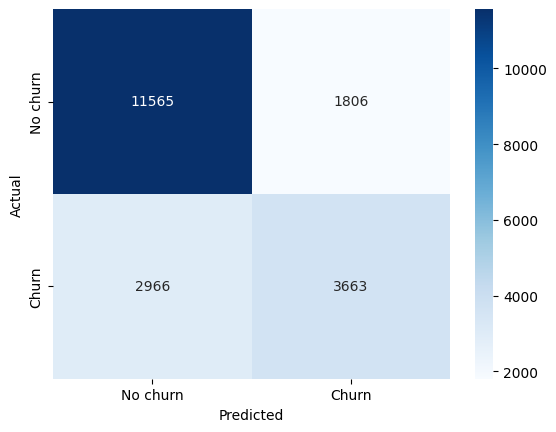

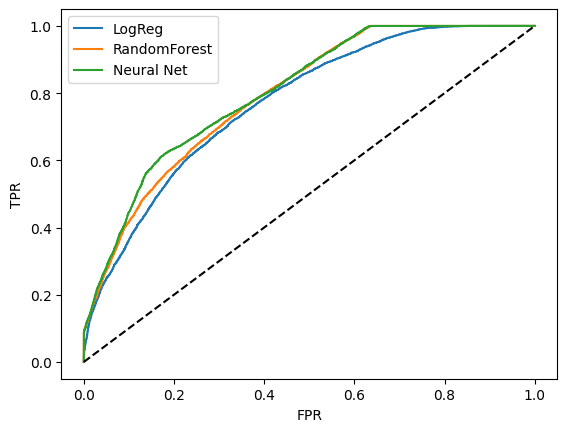

In [ ]:
nn_prob = model.predict(X_test_p).ravel()
results.append(evaluate('Neural Network', y_test, nn_prob))
comparison = pd.DataFrame(results).round(4)
display(comparison)

print(classification_report(y_test, (nn_prob >= 0.5).astype(int)))
sns.heatmap(confusion_matrix(y_test, (nn_prob >= 0.5).astype(int)),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['No churn','Churn'], yticklabels=['No churn','Churn'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

for name, p in [('LogReg', lr.predict_proba(X_test_p)[:,1]),
                ('RandomForest', rf.predict_proba(X_test_p)[:,1]),
                ('Neural Net', nn_prob)]:
    fpr, tpr, _ = roc_curve(y_test, p); plt.plot(fpr, tpr, label=name)
plt.plot([0,1],[0,1],'k--'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.show()

Save and download

In [ ]:
model.save('churn_model.keras')
import joblib; joblib.dump(preprocess, 'preprocess.joblib')
from google.colab import files
files.download('churn_model.keras'); files.download('preprocess.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>